[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Time-Series-Analysis/blob/main/Quantlets/Ch_12/TSA_ch12_seminar/TSA_ch12_seminar.ipynb)

# Time Series Analysis — Seminar 12: Spectral analysis

*Seminar notebook (self-study chapter). Daniel Traian Pele, Bucharest University of Economic Studies.*

- Frequency $\nu$ in cycles per observation, period $1/\nu$; periodogram $I(\nu_j) = |d(\nu_j)|^2$ (Shumway and Stoffer 2017, ch. 4).
- [Solved] tasks: full solution here and in the slides; [Proposed] tasks: write your own code in the empty cell.
- The seminar is for practice and is not graded; the solutions of [Proposed] tasks are discussed in class.

> Quantlet `TSA_ch12_seminar`: student version of the Seminar 12 notebook. Solved exercises (A1, A3, A5, B1) are shown with code and output; the proposed exercises (A2, A4, B2, C1) are not solved here (an empty code cell where they need code).

> The solutions are discussed in the seminar.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/TSA/Chapter_12'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


In [ ]:
import os
import re
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from scipy import optimize
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

## Chart style

- Transparent background, legend below the plot, course palette.

In [ ]:
# Palette (RGB values of latex/preamble.tex)
MainBlue = '#1A3A6E'
IDAred = '#CD0000'
Forest = '#2E7D32'
Amber = '#B5853F'
Orange = '#E67E22'
Purple = '#8E44AD'
Teal = '#17A2B8'
Crimson = '#DC3545'
DarkText = '#1F2A44'          # text, axes and ticks (dark navy, not grey)

PALETTE = [MainBlue, IDAred, Forest, Amber, Purple, Orange, Teal, Crimson]
# fixed colours for the series used in several chapters
COL = {'sp500': MainBlue, 'bet': IDAred, 'bettr': Orange, 'dax': Teal, 'btc': Amber, 'eth': Crimson,
       'eurron': Forest, 'gold': Purple, 'vix': Crimson, 'stoxx50': Forest, 'ndx': Teal}


def apply():
    """Set the course style for matplotlib."""
    rc = plt.rcParams
    rc['figure.facecolor'] = 'none'
    rc['axes.facecolor'] = 'none'
    rc['savefig.facecolor'] = 'none'
    rc['savefig.transparent'] = True
    rc['axes.grid'] = False
    rc['font.family'] = 'sans-serif'
    rc['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
    # default size about 7 inches wide (as in MFM); a chart is shown 11-13 cm wide on a slide, so these font sizes
    # give 7-9 pt text there. Multi-panel charts should stay near 7-7.6 inches wide: at 10-11 inches the axis
    # text drops to about 5 pt on the slide.
    rc['figure.figsize'] = (7.0, 3.4)
    rc['font.size'] = 12
    rc['axes.labelsize'] = 13
    rc['axes.titlesize'] = 13
    rc['xtick.labelsize'] = 11.5
    rc['ytick.labelsize'] = 11.5
    rc['legend.fontsize'] = 11
    rc['axes.spines.top'] = False
    rc['axes.spines.right'] = False
    rc['axes.linewidth'] = 0.6
    rc['lines.linewidth'] = 1.4
    rc['legend.facecolor'] = 'none'
    rc['legend.framealpha'] = 0
    rc['legend.frameon'] = False
    for k in ('text.color', 'axes.labelcolor', 'axes.edgecolor', 'xtick.color', 'ytick.color', 'axes.titlecolor'):
        rc[k] = DarkText
    rc['axes.prop_cycle'] = mpl.cycler(color=PALETTE)
    _remember_tight_layout()


def _remember_tight_layout():
    """Figure.tight_layout also stores its arguments on the figure, so that save_fig can re-apply the same layout
    after it has wrapped a label or changed the number of legend columns (see finalize)."""
    from matplotlib.figure import Figure
    if getattr(Figure.tight_layout, '_tsa', False):
        return
    orig = Figure.tight_layout

    def tight_layout(self, *a, **k):
        self._tsa_tight = (a, k)
        return orig(self, *a, **k)
    tight_layout._tsa = True
    Figure.tight_layout = tight_layout


def legend_outside_bottom(ax, ncol=2, y=-0.22, **kw):
    """Place the legend outside the plot, bottom centre (for a figure with several axes, pass the last one
    or use fig.legend with the same arguments)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False, **kw)


def fig_legend_bottom(fig, handles=None, labels=None, ncol=3, y=-0.02):
    """One legend for a whole figure (several panels), below the panels."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels and not l.startswith('_'):
                    handles.append(h)
                    labels.append(l)
    return fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def _is_grey(c, tol=0.06):
    try:
        r, g, b = to_rgb(c)
    except ValueError:
        return False
    return max(r, g, b) - min(r, g, b) < tol and 0.25 < (r + g + b) / 3 < 0.95


def check_no_grey(fig):
    """House rule: no grey series and no grey text. Raises ValueError listing the offending elements."""
    bad = []
    for ax in fig.axes:
        for ln in ax.get_lines():
            if not ln.get_label().startswith('_') and _is_grey(ln.get_color()):
                bad.append(f'line {ln.get_label()!r}')
        for coll in ax.collections:
            fc = coll.get_facecolor()
            if len(fc) and coll.get_label() and not coll.get_label().startswith('_') and _is_grey(fc[0][:3]):
                bad.append(f'series {coll.get_label()!r}')
        for t in ax.texts + [ax.title, ax.xaxis.label, ax.yaxis.label]:
            if t.get_text() and _is_grey(t.get_color()):
                bad.append(f'text {t.get_text()[:30]!r}')
    if bad:
        raise ValueError('grey elements: ' + ', '.join(bad))


def save_fig(name, out_dir=None, show=True):
    """Save the figure as transparent PDF and PNG (OUT_DIR if defined, else the current folder), then show it."""
    d = out_dir or globals().get('OUT_DIR', '.')
    plt.savefig(os.path.join(d, f'{name}.pdf'), bbox_inches='tight', transparent=True)
    plt.savefig(os.path.join(d, f'{name}.png'), bbox_inches='tight', transparent=True, dpi=180)
    if show:
        plt.show()
    plt.close()


apply()
# the chapter scripts call the style as st.<name> (import tsa_style as st): the same names here
import types
st = types.SimpleNamespace(COL=COL, PALETTE=PALETTE, MainBlue=MainBlue, IDAred=IDAred, Forest=Forest, Amber=Amber,
                           Orange=Orange, Purple=Purple, Teal=Teal, Crimson=Crimson, DarkText=DarkText, apply=apply, legend_outside_bottom=legend_outside_bottom,
                           fig_legend_bottom=fig_legend_bottom, save_fig=save_fig, check_no_grey=check_no_grey)

## Data

- Daily market data from EODHD, saved in `data/market` of the TSA repository; EUR/RON is the official BNR reference rate.
- Macroeconomic series: FRED (St. Louis Fed), Eurostat and the classic data sets of statsmodels.
- Returns in %: $r_t = 100(\ln P_t - \ln P_{t-1})$; each series on its own calendar.

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Time-Series-Analysis/main/data/market/'
# local copy of the course data, if the notebook runs inside the repository
MARKET_DIR = next((os.path.join(d, 'data', 'market') for d in ('.', '..', '../..', '../../..')
                   if os.path.isdir(os.path.join(d, 'data', 'market'))), '')
END = '2026-09-18'          # last day of the saved data

# name -> (symbol, label, group, field, default start)
SERIES = {
    # equity indices
    'sp500':    ('GSPC.INDX',     'S&P 500',               'Equity', 'close', '2000-01-01'),
    'ndx':      ('NDX.INDX',      'Nasdaq 100',            'Equity', 'close', '2000-01-01'),
    'dax':      ('GDAXI.INDX',    'DAX',                   'Equity', 'close', '2000-01-01'),
    'stoxx50':  ('STOXX50E.INDX', 'Euro Stoxx 50',         'Equity', 'close', '2000-01-01'),
    'nikkei':   ('N225.INDX',     'Nikkei 225',            'Equity', 'close', '2000-01-01'),
    'bet':      ('BET',           'BET',                   'Equity', 'close', '2000-01-01'),
    'bettr':    ('BETTR.INDX',    'BET-TR',                'Equity', 'close', '2014-09-23'),
    'betxt':    ('BETXT.INDX',    'BET-XT',                'Equity', 'close', '2011-08-12'),
    'betfi':    ('BETFI.INDX',    'BET-FI',                'Equity', 'close', '2012-01-25'),
    'wig20':    ('WIG20.INDX',    'WIG20',                 'Equity', 'close', '2000-01-01'),
    'bux':      ('BUX.INDX',      'BUX',                   'Equity', 'close', '2000-01-01'),
    'px':       ('PX.INDX',       'PX',                    'Equity', 'close', '2000-01-01'),
    'vix':      ('VIX.INDX',      'VIX',                   'Volatility', 'close', '2000-01-01'),
    # ETFs (adjusted close)
    'spy':      ('SPY.US',        'SPY',                   'ETF', 'adjusted_close', '2000-01-01'),
    'tlt':      ('TLT.US',        'TLT (US Treasuries 20y+)', 'ETF', 'adjusted_close', '2002-07-30'),
    'gld':      ('GLD.US',        'GLD (gold ETF)',        'ETF', 'adjusted_close', '2004-11-18'),
    'tvbetetf': ('TVBETETF.RO',   'TVBETETF',              'ETF', 'adjusted_close', '2015-06-12'),
    # Bucharest Stock Exchange (adjusted close)
    'tlv':      ('TLV.RO',        'Banca Transilvania',    'Stock', 'adjusted_close', '2000-01-01'),
    'snp':      ('SNP.RO',        'OMV Petrom',            'Stock', 'adjusted_close', '2001-09-04'),
    'brd':      ('BRD.RO',        'BRD',                   'Stock', 'adjusted_close', '2001-01-16'),
    'tgn':      ('TGN.RO',        'Transgaz',              'Stock', 'adjusted_close', '2008-01-25'),
    'sng':      ('SNG.RO',        'Romgaz',                'Stock', 'adjusted_close', '2013-11-12'),
    'snn':      ('SNN.RO',        'Nuclearelectrica',      'Stock', 'adjusted_close', '2013-11-04'),
    'h2o':      ('H2O.RO',        'Hidroelectrica',        'Stock', 'adjusted_close', '2023-07-12'),
    # US stocks (adjusted close)
    'aapl':     ('AAPL.US',       'Apple',                 'Stock', 'adjusted_close', '2000-01-01'),
    'msft':     ('MSFT.US',       'Microsoft',             'Stock', 'adjusted_close', '2000-01-01'),
    'nvda':     ('NVDA.US',       'NVIDIA',                'Stock', 'adjusted_close', '2000-01-01'),
    'jpm':      ('JPM.US',        'JPMorgan Chase',        'Stock', 'adjusted_close', '2000-01-01'),
    # crypto (close, 7 days a week)
    'btc':      ('BTC-USD.CC',    'Bitcoin',               'Crypto', 'close', '2014-09-17'),
    'eth':      ('ETH-USD.CC',    'Ethereum',              'Crypto', 'close', '2015-08-07'),
    'sol':      ('SOL-USD.CC',    'Solana',                'Crypto', 'close', '2020-04-11'),
    'usdt':     ('USDT-USD.CC',   'Tether (USDT)',         'Crypto', 'close', '2015-02-26'),
    # FX and commodities
    'eurron':   ('REF:EUR',       'EUR/RON (BNR reference)', 'FX', 'close', '2005-07-01'),
    'usdron':   ('REF:USD',       'USD/RON (BNR reference)', 'FX', 'close', '2005-07-01'),
    'eurron_eodhd': ('EURRON.FOREX', 'EUR/RON (EODHD)',    'FX', 'close', '2005-07-01'),
    'eurusd':   ('EURUSD.FOREX',  'EUR/USD',               'FX', 'close', '2002-05-06'),
    'gold':     ('XAUUSD.FOREX',  'Gold (XAU/USD)',        'Commodity', 'close', '2000-01-01'),
    # government bond yields (close, % p.a.)
    'us10y':    ('US10Y.GBOND',   'US 10Y yield',          'Yield', 'close', '2000-01-01'),
    'de10y':    ('DE10Y.GBOND',   'Germany 10Y yield',     'Yield', 'close', '2007-03-28'),
    'ro10y':    ('RO10Y.GBOND',   'Romania 10Y yield',     'Yield', 'close', '2007-08-17'),
}
LABELS = {k: v[1] for k, v in SERIES.items()}
_CACHE = {}


def read_market(symbol):
    """Daily table of one symbol: local copy of the course data, otherwise the TSA repository on GitHub."""
    fname = f'{symbol}.csv'
    path = os.path.join(MARKET_DIR, fname) if MARKET_DIR else ''
    src = path if path and os.path.exists(path) else REPO_RAW + fname
    return pd.read_csv(src, index_col='date', parse_dates=True).sort_index()


def read_reference_rate(currency='EUR', start='2005-07-01', end=END):
    """Official BNR reference rate (RON per unit of currency), from the public yearly XML archives."""
    key = (currency, start, end)
    if key in _CACHE:
        return _CACHE[key]
    rows = []
    for y in range(max(int(start[:4]), 2005), int(end[:4]) + 1):
        url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
        xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                     timeout=60).read().decode()
        for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
            m = re.search(rf'<Rate currency="{currency}"(?: multiplier="\d+")?>([\d.]+)</Rate>', body)
            if m:
                rows.append((d, float(m.group(1))))
    s = pd.DataFrame(rows, columns=['date', 'close']).drop_duplicates('date').set_index('date')['close']
    s.index = pd.to_datetime(s.index)
    _CACHE[key] = s.sort_index().loc[start:end]
    return _CACHE[key]


def load_close(name, start=None, end=END, field=None):
    """Daily closing price of a named series, cleaned with the course conventions."""
    symbol, label, group, field0, start0 = SERIES[name]
    start, field = start or start0, field or field0
    if symbol.startswith('REF:'):
        return read_reference_rate(symbol.split(':')[1], start=start, end=end).rename(name)
    t = read_market(symbol)
    s = (t[field] if field in t.columns else t['close']).loc[start:end]
    s = pd.to_numeric(s, errors='coerce').dropna()
    if group != 'Yield':
        s = s[s > 0]
    if group != 'Crypto':
        s = s[s.index.dayofweek < 5]          # no weekend quotes
        s = s[s.diff() != 0]                  # no holidays filled with the previous price
    s.index.name = 'date'
    return s.rename(name)


def load_ohlc(name, start=None, end=END):
    """Open, high, low, close (and volume) of a series with OHLC data (range-based volatility estimators)."""
    symbol, _, group, _, start0 = SERIES[name]
    t = read_market(symbol).loc[start or start0:end]
    cols = [c for c in ('open', 'high', 'low', 'close', 'volume') if c in t.columns]
    t = t[cols].dropna()
    if group != 'Crypto':
        t = t[t.index.dayofweek < 5]
    return t[(t[['open', 'high', 'low', 'close']] > 0).all(axis=1)] if 'open' in cols else t


def log_returns(name, start=None, end=END, pct=True):
    """Daily log returns r_t = ln P_t - ln P_{t-1} (in % by default), on the series' own calendar."""
    r = np.log(load_close(name, start, end)).diff().dropna()
    return (100 * r if pct else r).rename(name)


def simple_returns(name, start=None, end=END, pct=True):
    """Daily simple returns R_t = P_t / P_{t-1} - 1 (in % by default)."""
    r = load_close(name, start, end).pct_change().dropna()
    return (100 * r if pct else r).rename(name)


def load_panel(names, start=None, end=END, kind='close'):
    """Several series aligned on date: kind = 'close' or 'returns' (NaN where a market does not trade)."""
    f = load_close if kind == 'close' else log_returns
    return pd.concat([f(n, start, end) for n in names], axis=1)


def periods_per_year(r):
    """Average number of observations per calendar year (the actual frequency of the series)."""
    years = (r.index[-1] - r.index[0]).days / 365.25
    return len(r) / years


def read_fred(ids, start=None, end=None):
    """FRED series (St. Louis Fed) from the public fredgraph CSV, e.g. read_fred('UNRATE') or
    read_fred(['GDPC1', 'CPIAUCSL']). Returns a Series (one id) or a DataFrame (several ids)."""
    one = isinstance(ids, str)
    ids = [ids] if one else list(ids)
    out = []
    for sid in ids:
        key = ('fred', sid)
        if key not in _CACHE:
            url = f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}'
            t = pd.read_csv(url, index_col=0, parse_dates=True, na_values='.')
            _CACHE[key] = pd.to_numeric(t.iloc[:, 0], errors='coerce').rename(sid)
        out.append(_CACHE[key])
    df = pd.concat(out, axis=1).loc[start:end]
    df.index.name = 'date'
    return df.iloc[:, 0].dropna() if one else df


def _eurostat_period(p):
    p = str(p)
    if '-Q' in p:
        y, q = p.split('-Q')
        return pd.Timestamp(int(y), 3 * int(q) - 2, 1)
    if '-' in p and len(p) == 7:
        return pd.Timestamp(p + '-01')
    if len(p) == 4:
        return pd.Timestamp(int(p), 1, 1)
    return pd.Timestamp(p)


def read_eurostat(dataset, key, start=None):
    """One Eurostat series from the public SDMX 2.1 API (SDMX-CSV), e.g. Romanian quarterly real GDP,
    seasonally and calendar adjusted, chain-linked volumes (2010) in million EUR:
        read_eurostat('namq_10_gdp', 'Q.CLV10_MEUR.SCA.B1GQ.RO')
    `key` is the dot-separated series key of the dataset (dimensions in the order of the dataset)."""
    url = (f'https://ec.europa.eu/eurostat/api/dissemination/sdmx/2.1/data/{dataset}/{key}?format=SDMX-CSV'
           + (f'&startPeriod={start}' if start else ''))
    ck = ('eurostat', url)
    if ck not in _CACHE:
        t = pd.read_csv(url)
        s = pd.Series(pd.to_numeric(t['OBS_VALUE'], errors='coerce').values,
                      index=[_eurostat_period(p) for p in t['TIME_PERIOD']], name=f'{dataset}:{key}')
        s.index.name = 'date'
        _CACHE[ck] = s.sort_index().dropna()
    return _CACHE[ck]


def load_statsmodels(name):
    """Classic data sets shipped with statsmodels (offline): 'sunspots' (yearly, 1700-2008), 'co2' (weekly,
    Mauna Loa, 1958-2001), 'macrodata' (US quarterly macro, 1959-2009), 'nile' (yearly Nile flow, 1871-1970)."""
    import statsmodels.api as sm
    if name == 'sunspots':
        d = sm.datasets.sunspots.load_pandas().data
        s = d.set_index(pd.to_datetime(d['YEAR'].astype(int).astype(str)))['SUNACTIVITY']
        s.index.name = 'date'
        return s.rename('sunspots')
    if name == 'co2':
        return sm.datasets.co2.load_pandas().data['co2'].rename('co2')
    if name == 'macrodata':
        d = sm.datasets.macrodata.load_pandas().data
        d.index = pd.period_range('1959Q1', periods=len(d), freq='Q').to_timestamp()
        d.index.name = 'date'
        return d
    if name == 'nile':
        d = sm.datasets.nile.load_pandas().data
        s = d.set_index(pd.to_datetime(d['year'].astype(int).astype(str)))['volume']
        s.index.name = 'date'
        return s.rename('nile')
    raise KeyError(f'unknown statsmodels data set: {name}')

## Seminar functions

- Helpers of Chapter 12 (`periodogram`, `daniell`, `chi2_band`, `arma_spectrum`, `hp_gain`, `sunspots`, `gdp_growth`, `load_hourly`) and the seminar functions: `alias`, `fit_ar`, `band_share`, `hp_half_power`, `harmonic_share`, `ip_growth`, `a1_frequencies`, `a3_ar1_gdp`, `a5_gains`, `b1_load`.

In [ ]:
from scipy import signal
from statsmodels.tsa.filters.hp_filter import hpfilter
SEED = 2026
RO_GDP = ('namq_10_gdp', 'Q.CLV10_MEUR.SCA.B1GQ.RO')
GDP_END = '2019-12-31'
BC_BAND = (6, 32)
HP_LAMBDA = 1600
LOAD_FILE = 'ch4_ro_load_hourly.csv'
LOAD_RAW = 'https://raw.githubusercontent.com/danpele/Time-Series-Analysis/main/Quantlets/Ch_04/ch4_ro_load_hourly.csv'
BW = 0.65
AR2 = (1.5, -0.75)
DFT_EXAMPLE = [4.0, 2.0, 0.0, 2.0]
HERE = "."
LOAD_YEAR = '2025'
DFT_SEMINAR = [2.0, 6.0, 4.0, 0.0]
IP_SAMPLE = ('1948-01-01', '2019-12-01')
IP_BAND = (18, 96)
DANIELL_M = 3
LAMBDAS = {'quarterly': (1600, 4), 'monthly': (129600, 12), 'annual': (6.25, 1)}


def save(name, save_it=True):
    if save_it:
        st.check_no_grey(plt.gcf())
        st.save_fig(name)
    else:
        plt.show()


def periodogram(x, taper=False):
    """Periodogram I(nu_j) = |d(nu_j)|^2, d(nu_j) = T^(-1/2) sum_t x_t exp(-2 pi i nu_j t), at the Fourier
    frequencies nu_j = j / T, j = 1..[T/2] (mean removed). With taper=True a Hann (cosine bell) taper is applied
    and rescaled so that the total power is unchanged."""
    x = np.asarray(x, float)
    x = x - x.mean()
    T = len(x)
    if taper:
        w = 0.5 * (1 - np.cos(2 * np.pi * (np.arange(T) + 0.5) / T))
        x = x * w / np.sqrt(np.mean(w ** 2))
    I = np.abs(np.fft.fft(x)) ** 2 / T
    j = np.arange(1, T // 2 + 1)
    return j / T, I[j]


def daniell(I, m):
    """Daniell smoother: the average of the 2m + 1 periodogram ordinates around each frequency (reflected at the
    ends); approximately chi-square with df = 2(2m + 1) degrees of freedom."""
    if m == 0:
        return np.asarray(I, float)
    k = np.ones(2 * m + 1) / (2 * m + 1)
    return np.convolve(np.pad(np.asarray(I, float), m, mode='reflect'), k, mode='valid')


def chi2_band(fhat, df, level=0.95):
    """Approximate confidence interval for f(nu): [df fhat / chi2_df(1 - a/2), df fhat / chi2_df(a/2)]."""
    a = 1 - level
    return df * fhat / stats.chi2.ppf(1 - a / 2, df), df * fhat / stats.chi2.ppf(a / 2, df)


def welch(x, nperseg):
    """Welch estimate (Hann windows, 50% overlap), rescaled to the convention f(nu) = sum_h gamma(h) e^(-2 pi i nu h)."""
    nu, P = signal.welch(np.asarray(x, float) - np.mean(x), fs=1.0, window='hann', nperseg=nperseg)
    return nu[1:], P[1:] / 2


def arma_spectrum(nu, phi=(), theta=(), sigma2=1.0):
    """Spectral density of an ARMA(p,q): sigma^2 |theta(e^(-2 pi i nu))|^2 / |phi(e^(-2 pi i nu))|^2."""
    z = np.exp(-2j * np.pi * np.asarray(nu, float))
    num = np.ones_like(z) + sum(t * z ** (k + 1) for k, t in enumerate(theta))
    den = 1 - sum(p * z ** (k + 1) for k, p in enumerate(phi))
    return sigma2 * np.abs(num) ** 2 / np.abs(den) ** 2


def simulate_arma(phi, theta, T, seed=SEED, burn=500):
    rng = np.random.default_rng(seed)
    e = rng.standard_normal(T + burn)
    x = np.zeros(T + burn)
    for t in range(T + burn):
        x[t] = e[t] + sum(th * e[t - k - 1] for k, th in enumerate(theta) if t - k - 1 >= 0) \
            + sum(p * x[t - k - 1] for k, p in enumerate(phi) if t - k - 1 >= 0)
    return x[burn:]


def fisher_g(I):
    """Fisher's (1929) g test of a hidden periodicity: g = max I_j / sum I_j over j = 1..m (nu_j < 1/2), with the
    exact p-value P(g > x) = sum_k (-1)^(k-1) C(m, k) (1 - kx)^(m-1), k <= 1/x."""
    I = np.asarray(I, float)
    m = len(I)
    g = I.max() / I.sum()
    from math import comb
    p = sum((-1) ** (k - 1) * comb(m, k) * (1 - k * g) ** (m - 1) for k in range(1, int(1 / g) + 1))
    return {'g': float(g), 'm': int(m), 'p': float(min(max(p, 0.0), 1.0)), 'j': int(np.argmax(I) + 1)}


def gph_spec(x, m=None):
    """GPH (Geweke and Porter-Hudak 1983): OLS slope of log I(nu_j) on -log(4 sin^2(pi nu_j)), j = 1..m, is d;
    standard error pi / sqrt(24 m)."""
    nu, I = periodogram(x)
    m = m or int(np.floor(len(x) ** BW))
    X = -np.log(4 * np.sin(np.pi * nu[:m]) ** 2)
    b = np.polyfit(X, np.log(I[:m]), 1)
    return {'d': float(b[0]), 'c': float(b[1]), 'se': float(np.pi / np.sqrt(24 * m)), 'm': int(m),
            'nu_m': float(nu[m - 1])}


def morlet_cwt(x, periods, w0=6.0):
    """Continuous wavelet transform with a Morlet wavelet (Torrence and Compo 1998), computed by FFT;
    returns the wavelet power |W(s, t)|^2 / variance for the given Fourier periods (in observations)."""
    x = np.asarray(x, float)
    x = (x - x.mean()) / x.std()
    T = len(x)
    n = 1 << int(np.ceil(np.log2(2 * T)))
    xf = np.fft.fft(x, n)
    om = 2 * np.pi * np.fft.fftfreq(n)
    fourier_factor = 4 * np.pi / (w0 + np.sqrt(2 + w0 ** 2))
    P = np.zeros((len(periods), T))
    for i, per in enumerate(periods):
        s = per / fourier_factor
        psi = np.pi ** -0.25 * np.sqrt(2 * np.pi * s) * np.exp(-0.5 * (s * om - w0) ** 2) * (om > 0)
        P[i] = np.abs(np.fft.ifft(xf * psi)[:T]) ** 2
    return P


def sunspots():
    """Yearly mean sunspot number 1700-2008 (Wolf / SILSO series as shipped with statsmodels)."""
    s = load_statsmodels('sunspots')
    s.index = s.index.year
    return s


def gdp_growth(end=GDP_END):
    """Quarterly growth of real GDP, 100 x log difference: United States (FRED GDPC1) and Romania (Eurostat)."""
    us = read_fred('GDPC1').loc[:end]
    ro = read_eurostat(*RO_GDP).loc[:end]
    return {'US': (100 * np.log(us)).diff().dropna(), 'RO': (100 * np.log(ro)).diff().dropna(),
            'US_level': 100 * np.log(us), 'RO_level': 100 * np.log(ro)}


def hp_cycle(level, lam=HP_LAMBDA):
    cyc, trend = hpfilter(level, lamb=lam)
    return cyc


def load_hourly():
    """Hourly electricity load of Romania, MW (ENTSO-E extract of Chapter 4), on a regular UTC hourly grid."""
    s = None
    local = [os.path.join(HERE, '..', 'Ch_04', LOAD_FILE)] + [os.path.join(d, 'Quantlets', 'Ch_04', LOAD_FILE)
                                                                for d in ('.', '..', '../..', '../../..')]
    for src in [p for p in local if os.path.exists(p)] + [LOAD_RAW]:
        try:
            s = pd.read_csv(src, index_col=0, parse_dates=True).iloc[:, 0]
            break
        except Exception:
            continue
    s = s[~s.index.duplicated()].sort_index()
    s = s.reindex(pd.date_range(s.index[0], s.index[-1], freq='h')).interpolate()
    return s.rename('load_MW')


def hp_gain(nu, lam=HP_LAMBDA):
    """Gain of the HP cycle filter (real and nonnegative): G = 4 lam (1 - cos w)^2 / (1 + 4 lam (1 - cos w)^2),
    w = 2 pi nu; the squared gain is G^2 and the trend filter has gain 1 - G."""
    a = 4 * lam * (1 - np.cos(2 * np.pi * nu)) ** 2
    return a / (1 + a)


def alias(nu):
    """Apparent frequency (cycles per observation, in [0, 1/2]) of a cycle with nu cycles per observation."""
    return float(abs(nu - round(nu)))


def fit_ar(x, p):
    """OLS fit of an AR(p) with a constant: coefficients phi_1..phi_p and the residual variance (divisor n - p - 1)."""
    x = np.asarray(x, float)
    X = np.column_stack([np.ones(len(x) - p)] + [x[p - k:len(x) - k] for k in range(1, p + 1)])
    b, *_ = np.linalg.lstsq(X, x[p:], rcond=None)
    e = x[p:] - X @ b
    return b[1:], float(e @ e / (len(e) - p - 1)), float(b[0])


def band_share(nu_lo, nu_hi, phi=(), sigma2=1.0, theta=()):
    """Share of the variance of an ARMA process in the band nu_lo <= nu <= nu_hi (both sides of the spectrum)."""
    nu = np.linspace(0, 0.5, 20001)
    f = arma_spectrum(nu, phi, theta, sigma2)
    m = (nu >= nu_lo) & (nu <= nu_hi)
    return float(np.trapezoid(f[m], nu[m]) / np.trapezoid(f, nu))


def hp_half_power(lam):
    """Frequency at which the squared gain of the HP cycle filter equals 1/2: 4 lam (1 - cos w)^2 = 1 / (sqrt 2 - 1)."""
    a = 1 / (np.sqrt(2) - 1)
    w = np.arccos(1 - np.sqrt(a / (4 * lam)))
    return float(w / (2 * np.pi))


def harmonic_share(I, T, periods, width=2):
    """Share of the total periodogram in +-width Fourier frequencies around each period (in observations)."""
    idx = set()
    for p in periods:
        j = int(round(T / p))
        idx.update(range(max(j - width, 1) - 1, min(j + width, len(I))))
    return float(I[sorted(idx)].sum() / I.sum())


def ip_growth():
    ip = read_fred('INDPRO').loc[IP_SAMPLE[0]:IP_SAMPLE[1]].dropna()
    return (100 * np.log(ip)).diff().dropna()


def a1_frequencies():
    """Fourier frequencies of one year of hourly data; aliasing of the daily and half-daily cycles."""
    T = 365 * 24
    out = {'T': T, 'j24': T / 24, 'j12': T / 12, 'j168': T / 168, 'j168_round': int(round(T / 168)),
           'p168_round': T / round(T / 168), 'nyq_period': 2.0}
    cases = {'daily_every_24h': (24, 24), 'half_daily_every_8h': (8, 12), 'daily_every_25h': (25, 24),
             'weekly_daily': (24, 168)}
    for k, (dt, period) in cases.items():
        nu = dt / period
        a = alias(nu)
        out[k] = {'dt': dt, 'period': period, 'nu': nu, 'alias': a, 'alias_period_obs': (1 / a if a > 0 else None),
                  'alias_period_hours': (dt / a if a > 0 else None)}
    return out


def a3_ar1_gdp():
    """AR(1) fitted to US real GDP growth (quarterly, 1947-2019): its spectrum at nu = 0, 1/4, 1/2 and the share of
    the variance in the business-cycle band (6-32 quarters), against the share in the periodogram of the data."""
    x = gdp_growth()['US'].values
    phi, s2, c = fit_ar(x, 1)
    phi = float(phi[0])
    f = {str(nu): float(arma_spectrum(nu, [phi], (), s2)) for nu in (0.0, 0.25, 0.5)}
    nuj, I = periodogram(x)
    band = (nuj >= 1 / BC_BAND[1]) & (nuj <= 1 / BC_BAND[0])
    return {'T': int(len(x)), 'phi': phi, 's2': s2, 'f': f, 'ratio': f['0.0'] / f['0.5'],
            'ratio_formula': ((1 + phi) / (1 - phi)) ** 2, 'gamma0': s2 / (1 - phi ** 2), 'var_data': float(np.var(x, ddof=1)),
            'share_ar1': band_share(1 / BC_BAND[1], 1 / BC_BAND[0], [phi], s2), 'share_data': float(I[band].sum() / I.sum()),
            'share_wn': float((1 / BC_BAND[0] - 1 / BC_BAND[1]) / 0.5)}


def a5_gains():
    """Squared gains of the first difference (4 sin^2(pi nu)) and of the HP cycle filter at chosen periods; the zeros
    of the seasonal difference 1 - L^12; the half-power period of the HP filter for three lambdas."""
    out = {'d1': {str(p): float(4 * np.sin(np.pi / p) ** 2) for p in (2, 4, 8, 32)},
           'hp': {str(p): float(hp_gain(1 / p, HP_LAMBDA) ** 2) for p in (6, 8, 32, 40)},
           'd12_zeros': [12 / k for k in range(1, 7)], 'a': float(1 / (np.sqrt(2) - 1))}
    for k, (lam, per_year) in LAMBDAS.items():
        nu = hp_half_power(lam)
        out[k] = {'lam': lam, 'nu': nu, 'period_obs': 1 / nu, 'period_years': 1 / nu / per_year,
                  'cos': float(1 - np.sqrt(out['a'] / (4 * lam)))}
    return out


def b1_load(save_it=True):
    """Hourly load of Romania in 2025 (UTC hours): periodogram, the six largest peaks (distinct periods), the share of
    the variance at the daily and weekly harmonics; the daily share month by month."""
    s = load_hourly().loc[LOAD_YEAR] / 1000          # GW
    x = s.values
    T = len(x)
    nu, I = periodogram(x)
    daily = [24 / k for k in range(1, 7)]
    weekly = [168 / k for k in range(1, 7)] + [336]
    sh_d, sh_w = harmonic_share(I, T, daily), harmonic_share(I, T, weekly)
    order = np.argsort(I)[::-1]
    top = []
    for k in order:
        p = 1 / nu[k]
        if all(abs(p - q[0]) / q[0] > 0.05 for q in top):
            top.append((float(p), float(I[k] / I.sum())))
        if len(top) == 6:
            break
    monthly = {}
    for m, g in s.groupby(s.index.month):
        n2, I2 = periodogram(g.values)
        monthly[int(m)] = harmonic_share(I2, len(g), daily, width=1)
    fig, axes = plt.subplots(1, 2, figsize=(9.33, 2.62), gridspec_kw={'width_ratios': [1.5, 1]})
    ax = axes[0]
    ax.loglog(1 / nu, I, color=st.MainBlue, lw=0.5, label='periodogram, 2025')
    for p, lab in ((168, '168 h'), (24, '24 h'), (12, '12 h')):
        ax.axvline(p, color=st.IDAred, lw=0.8, ls=':', label='daily and weekly periods' if p == 168 else '_')
        ax.text(p, I.max() * 3, lab, rotation=90, va='top', ha='right', color=st.IDAred, fontsize=10)
    ax.set_xlabel('period (hours, log scale)')
    ax.set_ylabel('I(nu) (log scale)')
    ax.invert_xaxis()
    axes[1].bar(list(monthly), [100 * v for v in monthly.values()], color=st.Forest, label='daily harmonics, % of monthly variance')
    axes[1].set_xticks(range(1, 13))
    axes[1].set_xlabel('month of 2025')
    st.fig_legend_bottom(fig, ncol=3, y=0.04)
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    save('ch12_sem_b1', save_it)
    mx, mn = max(monthly, key=monthly.get), min(monthly, key=monthly.get)
    return {'T': int(T), 'start': str(s.index[0]), 'end': str(s.index[-1]), 'mean': float(s.mean()), 'var': float(s.var()),
            'share_daily': sh_d, 'share_weekly': sh_w, 'top': top, 'monthly': monthly, 'max_month': int(mx),
            'max_share': monthly[mx], 'min_month': int(mn), 'min_share': monthly[mn], 'j24': int(round(T / 24)),
            'j168': int(round(T / 168))}

# Part A: computations on paper

- Do each computation on paper first; then check it with the code.

## A1 [Solved]: frequencies, periods and aliasing

**Context.** One year of hourly load, $T = 8760$.

1. Find the Fourier index of the 24-, 12- and 168-hour cycles.
2. Give the shortest visible period.
3. Where do the daily and 12-hour cycles appear when the meter is read every 24, 8 or 25 hours?

**Report:** three indices, one period, three apparent frequencies.

In [7]:
# Solution
a1_frequencies()

{'T': 8760,
 'j24': 365.0,
 'j12': 730.0,
 'j168': 52.142857142857146,
 'j168_round': 52,
 'p168_round': 168.46153846153845,
 'nyq_period': 2.0,
 'daily_every_24h': {'dt': 24,
  'period': 24,
  'nu': 1.0,
  'alias': 0.0,
  'alias_period_obs': None,
  'alias_period_hours': None},
 'half_daily_every_8h': {'dt': 8,
  'period': 12,
  'nu': 0.6666666666666666,
  'alias': 0.33333333333333337,
  'alias_period_obs': 2.9999999999999996,
  'alias_period_hours': 23.999999999999996},
 'daily_every_25h': {'dt': 25,
  'period': 24,
  'nu': 1.0416666666666667,
  'alias': 0.04166666666666674,
  'alias_period_obs': 23.999999999999957,
  'alias_period_hours': 599.999999999999},
 'weekly_daily': {'dt': 24,
  'period': 168,
  'nu': 0.14285714285714285,
  'alias': 0.14285714285714285,
  'alias_period_obs': 7.0,
  'alias_period_hours': 168.0}}

**Interpretation of the result.** $j$ = 365 and 730 for the daily and 12-hour cycles; $8760/168$ = 52.14 is not an integer. A 12-hour cycle read every 8 hours looks like a 24-hour cycle.

## A2 [Proposed]: the periodogram of four values

**Context.** $x = (2, 6, 4, 0)$. Model: A1.

1. Remove the mean; list the Fourier frequencies.
2. Compute $d(\nu_j)$ and $I(\nu_j)$.
3. Check Parseval; which period carries the variance?

**Report:** three ordinates, one check, one period.

In [ ]:
# Your code here


## A3 [Solved]: the AR(1) spectrum of US GDP growth

1. Fit an AR(1) and compute $f(0)$, $f(1/4)$, $f(1/2)$ and $f(0)/f(1/2)$.
2. Compare $\gamma(0)$ with the sample variance.
3. Compare the business-cycle share (6-32 quarters) of the AR(1), the data and white noise.

**Report:** three values, one ratio, one variance, one share.

In [9]:
# Solution
a3_ar1_gdp()

{'T': 291,
 'phi': 0.35832476784223816,
 's2': 0.7523324788400452,
 'f': {'0.0': 1.8271712717022064,
  '0.25': 0.6667269758447948,
  '0.5': 0.407758076226516},
 'ratio': 4.481017981571956,
 'ratio_formula': 4.481017981571956,
 'gamma0': 0.8631592220938432,
 'var_data': 0.861522892405531,
 'share_ar1': 0.4325423963820524,
 'share_data': 0.48774650159151073,
 'share_wn': 0.2708333333333333}

**Interpretation of the result.** $\hat\phi$ = 0.358; $f(0)/f(1/2)$ = 4.48; the share of 6-32 quarters is 43.3% for the AR(1), 48.8% in the data and 27.1% for white noise.

## A4 [Proposed]: the AR(2) spectrum of the sunspots

**Context.** Yearly sunspots 1700-2008. Model: A3.

1. Fit an AR(2); show that the roots are complex.
2. Compute the peak frequency and its period.
3. Compare with the ACF period and the periodogram peak.

**Report:** one discriminant, one frequency, three periods.

In [ ]:
# Your code here


## A5 [Solved]: what do differences and the HP filter keep?

1. Squared gain of $1 - L$ at periods 2, 4, 8, 32.
2. Squared HP cycle gain at 8, 32, 40 quarters.
3. The half-power period for $\lambda$ = 1600, 129600 and 6.25.

**Report:** four gains, three gains, three periods in years.

In [11]:
# Solution
a5_gains()

{'d1': {'2': 4.0,
  '4': 1.9999999999999996,
  '8': 0.585786437626905,
  '32': 0.038429439193539104},
 'hp': {'6': 0.9987511708991998,
  '8': 0.9963671612459405,
  '32': 0.4937014515264566,
  '40': 0.2424672410055462},
 'd12_zeros': [12.0, 6.0, 4.0, 3.0, 2.4, 2.0],
 'a': 2.4142135623730945,
 'quarterly': {'lam': 1600,
  'nu': 0.031418792180076184,
  'period_obs': 31.82808537860144,
  'period_years': 7.95702134465036,
  'cos': 0.9805778253246246},
 'monthly': {'lam': 129600,
  'nu': 0.010457814518337638,
  'period_obs': 95.62227349189578,
  'period_years': 7.968522790991315,
  'cos': 0.997841980591625},
 'annual': {'lam': 6.25,
  'nu': 0.12897113894383946,
  'period_obs': 7.753672706848394,
  'period_years': 7.753672706848394,
  'cos': 0.6892452051939926}}

**Interpretation of the result.** The half-power period is 7.96 years for $\lambda$ = 1600, 7.97 for 129600 and 7.75 for 6.25.

# Part B: real data and interpretation

## B1 [Solved]: cycles of the Romanian electricity load

1. Compute the periodogram of 2025 and list the six largest peaks.
2. Compute the shares of the daily and weekly harmonics.
3. Repeat the daily share month by month.
4. Interpretation: why is the 12-hour peak so large, and why does the daily share change?

**Report:** six peaks, two shares, two months, one sentence.

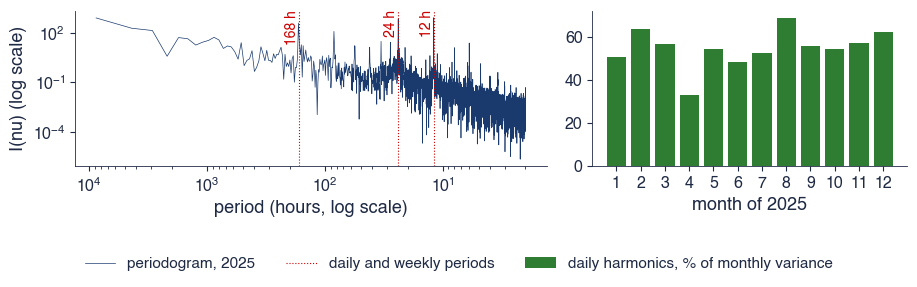

{'T': 8760, 'start': '2025-01-01 00:00:00', 'end': '2025-12-31 23:00:00', 'mean': 6.109756158961187, 'var': 1.0607508388579598, 'share_daily': 0.38976548843823844, 'share_weekly': 0.16333910510983057, 'top': [(12.0, 0.18011440537981366), (8760.0, 0.17460224606966848), (24.0, 0.15125121772379246), (168.46153846153845, 0.08561971708969042), (4380.0, 0.041565122238889175), (2920.0, 0.03017896641413008)], 'max_month': 8, 'max_share': 0.6870670589603811, 'min_month': 4, 'min_share': 0.3323326248583695, 'j24': 365, 'j168': 52}
{1: 0.507, 2: 0.637, 3: 0.567, 4: 0.332, 5: 0.546, 6: 0.484, 7: 0.527, 8: 0.687, 9: 0.559, 10: 0.542, 11: 0.572, 12: 0.623}


In [12]:
# Solution
b1 = b1_load(save_it=False)
print({k: v for k, v in b1.items() if k != 'monthly'})
print({m: round(v, 3) for m, v in b1['monthly'].items()})

**Interpretation of the result.** Daily harmonics 39.0% and weekly 16.3% of the variance; the daily share is largest in August (69%) and smallest in April (33%).

## B2 [Proposed]: the business cycle in US industrial production

**Question.** Is there a significant peak at 18-96 months, and does a low-order AR spectrum find it? Model: B1.

1. Smooth the periodogram with a Daniell window of $L = 7$.
2. Find the peak in the band and its 95% interval.
3. Compute the share of the band.
4. Fit AR($p$) by BIC and compare.

**Report:** one bandwidth, one interval, two shares, one AR order, one sentence.

In [ ]:
# Your code here


# Part C: AI critique

## C1 [Proposed]: audit an AI answer

- (a) the sunspot periodogram peaks at nu = 0.09, so the solar cycle lasts 0.09 years;
- (b) with more data the raw periodogram converges to the true spectrum;
- (c) daily data cannot show a weekly cycle, because the Nyquist frequency is 0.5;
- (d) every AR(2) with phi2 < 0 has a spectral peak inside (0, 1/2);
- (e) the HP filter with lambda = 1600 removes every fluctuation longer than 8 years;
- (f) a 95% Daniell interval with L = 5 is the estimate plus or minus 1.96 standard errors.

1. For each statement, say whether it is correct; if not, give the correct statement and the correct number.

**Report:** six verdicts with one line of justification each.

In [ ]:
# Your code here
